In [20]:
import sympy as sp
import numpy as np
from IPython.display import Math, display
import matplotlib.pyplot as plt
from sympy import pi

## Aufgabe 2.3

In [21]:
from scipy.integrate import quad

def dot_num(u, v):
    # u, v: Python-Funktionen t -> float
    val, _ = quad(lambda s: u(s) * v(s), -np.pi, np.pi)
    return val

In [22]:
n=5
t,k = sp.symbols('t k')

In [23]:
def x(t):
    return np.cos(t)

In [24]:
basisset1 = [lambda t, k=k: t**k for k in range(n+1)]
basisset2 = [lambda t, k=k: np.exp(-(t - (-np.pi + k*2*np.pi/5))**2) for k in range(n+1)]

In [25]:
lam = sp.symbols('lambda:'+str(n+1))

In [26]:
eqns1 = []
eqns2 = []
for i in range(n+1):
    eqns1.append(dot_num(x, basisset1[i]) - np.sum([lam[k] * dot_num(basisset1[k], basisset1[i]) for k in range(n + 1)]))
    eqns2.append(dot_num(x, basisset2[i]) - np.sum([lam[k] * dot_num(basisset2[k], basisset2[i]) for k in range(n + 1)]))
    display(Math(sp.latex(eqns1[-1]) + ' = 0'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [27]:
sol1 = sp.solve(eqns1,lam)
sol2 = sp.solve(eqns2,lam)
(sol1, sol2)

({lambda0: 0.978326390892334,
  lambda1: 0.0,
  lambda2: -0.452287810766557,
  lambda3: 0.0,
  lambda4: 0.0261598203821651,
  lambda5: 0.0},
 {lambda0: -0.942277913312285,
  lambda1: -0.273415310926243,
  lambda2: 0.734253723311044,
  lambda3: 0.734253723311044,
  lambda4: -0.273415310926243,
  lambda5: -0.942277913312285})

In [28]:
coefs1 = np.array([sol1[lami] for lami in lam])
coefs2 = np.array([sol2[lami] for lami in lam])
(coefs1, coefs2)

(array([0.978326390892334, 0.0, -0.452287810766557, 0.0,
        0.0261598203821651, 0.0], dtype=object),
 array([-0.942277913312285, -0.273415310926243, 0.734253723311044,
        0.734253723311044, -0.273415310926243, -0.942277913312285],
       dtype=object))

In [31]:
def p1(t):
    return sum(c * phi(t) for c, phi in zip(coefs1, basisset1))

def p2(t):
    return sum(c * phi(t) for c, phi in zip(coefs2, basisset2))

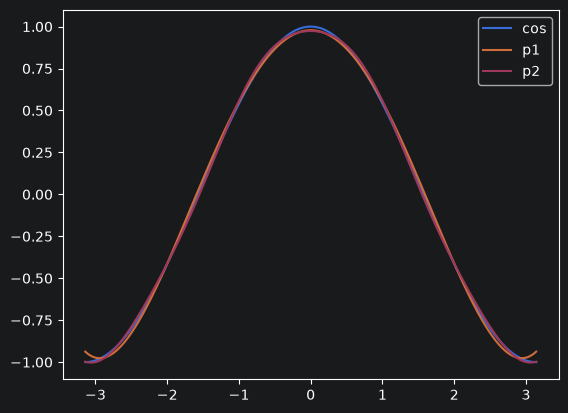

In [34]:
tp = np.linspace(-np.pi, np.pi, 400)
plt.plot(tp, np.cos(tp), label='cos')
plt.plot(tp, p1(tp), label='p1')
plt.plot(tp, p2(tp), label='p2')
plt.legend()
plt.show()

In [35]:
err1 = np.sqrt(dot_num(lambda s: x(s) - p1(s), lambda s: x(s) - p1(s)))
err2 = np.sqrt(dot_num(lambda s: x(s) - p2(s), lambda s: x(s) - p2(s)))
(err1, err2)

(np.float64(0.046015769281901306), np.float64(0.035721673452798294))